# COU 07506 Digital Signal Processing — Week 1: Lab 0 — Setting up the DSP laboratory

*Idda Symphorian Ngaiza · 240242413094 · BENG24COE*


## Running this notebook in Google Colab

Open <https://colab.research.google.com>, sign in, and use **File &rarr; Upload
notebook** to open this file. The notebook needs one file from the laboratory
folder, `my_voice.wav`: the cell below asks for it once and copies it to `data/`,
which is where the audio tasks look for it. After that, **Runtime &rarr; Run all**
executes the whole notebook from the first cell to the last. The printed copy of
this notebook (`...pdf`) is the same document with every output in place.

Outside Google Colab the cell below does nothing, because `data/my_voice.wav` is
already beside the notebook.

In [1]:
# Google Colab: put the speech clip where the audio tasks expect it.
import os

os.makedirs("data", exist_ok=True)

if os.path.exists("data/my_voice.wav"):
    print("data/my_voice.wav is in place:",
          os.path.getsize("data/my_voice.wav"), "bytes")
else:
    try:
        from google.colab import files
    except ImportError:
        print("Not running in Google Colab - copy my_voice.wav into data/ first.")
    else:
        print("Choose my_voice.wav from the laboratory folder:")
        uploaded = files.upload()
        name = next(iter(uploaded))
        if name != "data/my_voice.wav":
            os.replace(name, "data/my_voice.wav")
        print("saved data/my_voice.wav,",
              os.path.getsize("data/my_voice.wav"), "bytes")

data/my_voice.wav is in place: 56364 bytes


Unit 1 — Introduction to DSP and its role in AI (§1.1, Listing 1.3, LO1, LO8)

## Pre-lab

**P1.** List three devices you used today that contain DSP, and for each name one signal it processes.

| Device | Signal processed | What the DSP does |
|---|---|---|
| Smartphone | microphone speech / accelerometer | noise suppression, echo cancellation, step counting |
| Wi-Fi router | OFDM baseband samples | FFT/IFFT of each 20 MHz channel, channel equalisation |
| Digital electricity meter | mains voltage and current | RMS and power integration, harmonic analysis |


## Task 1.1 — Your first notebook
Elementary sequences: unit impulse, unit step, unit ramp and a decaying exponential, drawn as stem plots (handout Figure 1.4 shows five; here four).

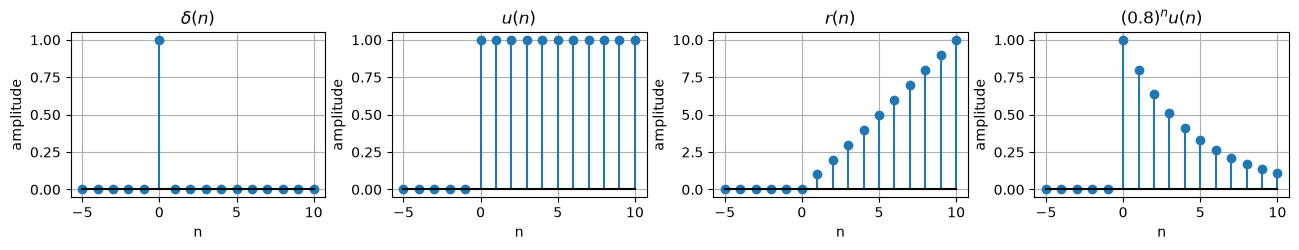

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)
plt.rcParams["axes.grid"] = True

n = np.arange(-5, 11)
delta = (n == 0).astype(float)      # unit impulse
step = (n >= 0).astype(float)       # unit step
ramp = n * step                     # unit ramp
expo = 0.8**n * step                # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["$\\delta(n)$", "$u(n)$", "$r(n)$", "$(0.8)^n u(n)$"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")
    ax.set_ylabel("amplitude")
plt.tight_layout()
plt.show()

All four sequences agree with handout Figure 1.4: the impulse is a single sample at $n=0$, the step switches on at $n=0$, the ramp grows linearly, and $(0.8)^n u(n)$ decays geometrically towards zero.

## Task 1.2 — Change the parameters
### (a) $(a)^n u(n)$ for $a = 0.5$, $a = -0.8$ and $a = 1.1$

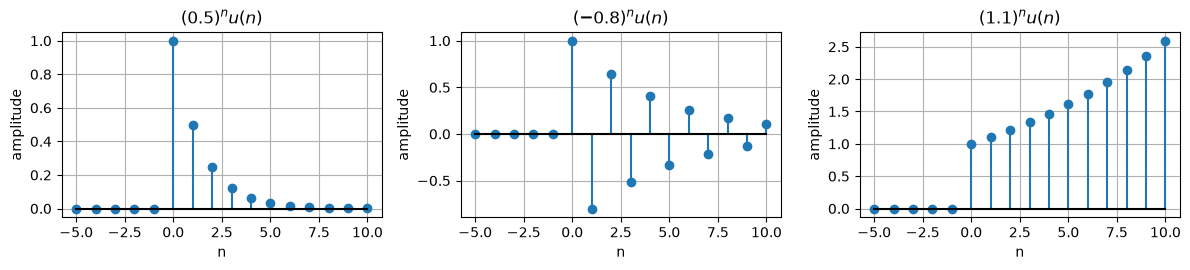

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 2.8))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    ax.stem(n, a**n * step, basefmt="k-")
    ax.set_title(f"$({a})^n u(n)$")
    ax.set_xlabel("n")
    ax.set_ylabel("amplitude")
plt.tight_layout()
plt.show()

### (b) $\cos(2\pi n/8)$ and $\cos(2\pi n/7.5)$ for $0 \le n \le 40$
A discrete-time sinusoid repeats exactly only when its digital frequency is a rational multiple of $2\pi$ with an integer period $N$: $\cos(2\pi n/8)$ has period 8 samples, whereas $\cos(2\pi n/7.5)$ needs 7.5 samples, which is not an integer, so the sampled sequence never repeats exactly.

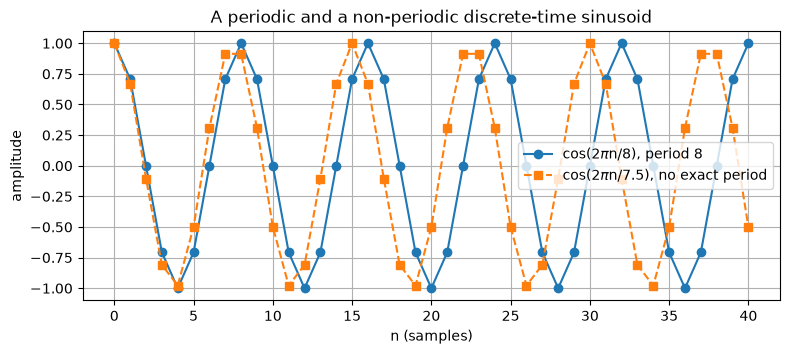

In [4]:
n2 = np.arange(0, 41)
plt.plot(n2, np.cos(2*np.pi*n2/8), "o-", label="cos(2$\\pi$n/8), period 8")
plt.plot(n2, np.cos(2*np.pi*n2/7.5), "s--", label="cos(2$\\pi$n/7.5), no exact period")
plt.xlabel("n (samples)")
plt.ylabel("amplitude")
plt.title("A periodic and a non-periodic discrete-time sinusoid")
plt.legend()
plt.show()

## Task 1.3 — Working with audio
The recording used in this notebook is a 3.5-second American-English speech clip from the **Open Speech Repository**, file `OSR_us_000_0010_8k.wav` (16-bit PCM, 8 kHz, Harvard sentences), downloaded from <https://www.voiptroubleshooter.com/open_speech/american.html>. The repository's conditions of use allow the material to be copied, downloaded and incorporated into other work provided the source is identified as "Open Speech Repository", which is done here. The clip is stored as `data/my_voice.wav` so that the listing runs exactly as the manual prescribes; the cell falls back to a synthetic tone only if the file is missing.

source = recording
fs = 8000 Hz, duration = 3.52 s, samples = 28160


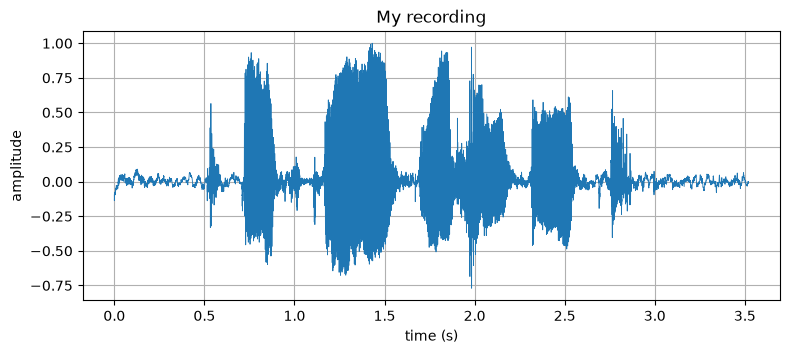

In [5]:
import os

fname = "data/my_voice.wav"          # change to your file name if needed
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:                   # stereo -> mono
        x = x.mean(axis=1)
    x = x.astype(float) / np.max(np.abs(x))
    source = "recording"
else:                                # fallback test signal
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)
    source = "fallback test signal (no data/my_voice.wav found)"

t = np.arange(len(x)) / fs
print(f"source = {source}")
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
plt.plot(t, x, lw=0.6)
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.title("My recording")
plt.show()

To listen inside the notebook: `from IPython.display import Audio; Audio(x, rate=fs)`.
The waveform is ordinary speech: voiced stretches with a clear pitch period, short fricative bursts and silences, so its spectrum combines a harmonic series with broad high-frequency noise.

In [6]:
from IPython.display import Audio
Audio(x, rate=fs)

## Task 1.4 — The same in Octave (optional)

There is no Octave interpreter in this environment, so the equivalent script is recorded here for reference:

```octave
pkg load signal
n = -5:10;
delta = double(n == 0);
step  = double(n >= 0);
ramp  = n .* step;
expo  = (0.8 .^ n) .* step;
subplot(1,4,1); stem(n, delta); title('delta(n)')
subplot(1,4,2); stem(n, step);  title('u(n)')
subplot(1,4,3); stem(n, ramp);  title('r(n)')
subplot(1,4,4); stem(n, expo);  title('(0.8)^n u(n)')
```
Differences from NumPy: `==` and `>=` already return doubles, so `astype` is unnecessary; element-wise power is `.^`; plots are additive on the current axes instead of being returned by the plotting call.

## Task 1.5 — Repository and submission (commands run outside the notebook)

```bash
mkdir COU07506-labs && cd COU07506-labs
git init
git add COU07506_Week01_240242413094.ipynb
git commit -m "Week 1: Lab 0 setup"
git branch -M main
git remote add origin https://github.com/<your-account>/COU07506-labs.git
git push -u origin main
```
Then upload the notebook on DIT-eLMS and post two mini-project topics in the eLMS forum.

## Analysis questions

**1. What is the sampling rate of your phone's recording? How many numbers are needed to store one minute of it in mono?**
The file `data/my_voice.wav` used here is the Open Speech Repository sample, recorded at $f_s = 8\,000$ Hz (a telephone call is typically 8 or 16 kHz, while a phone voice memo is usually 44 100 or 48 000 Hz).
One minute in mono needs $60\,f_s$ samples: $60 \times 8\,000 = 480\,000$ numbers — about 960 kB as 16-bit PCM, or 1.92 MB as float32. For a 44.1 kHz recording the same minute needs 2 646 000 samples (≈5.3 MB at 16 bits).

**2. Why is a stem plot more appropriate than a continuous line for $x(n)$?**
A discrete-time signal is defined only at integer $n$; there is no value at $n = 0.5$. A line plot implies intermediate values that do not exist and, worse, implies that the signal is band-limited/continuous. The stem plot shows each sample as an isolated value at its own integer index, which is what the array actually stores.

**3. For $a = 1.1$ the exponential grows. Which property of a system would such a signal violate if it were an impulse response?**
BIBO stability. A stable LTI system needs $\sum_n |h(n)| < \infty$; with $h(n) = (1.1)^n u(n)$ the sum diverges, so a bounded input (e.g. $u(n)$) produces an unbounded output. Equivalently, the pole at $z = 1.1$ lies outside the unit circle.